**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки

import os
import sys
import warnings
import subprocess
import importlib.util

warnings.filterwarnings("ignore")

# Встановлення бібліотек, якщо їх немає в середовищі
def install_if_missing(module_name, package_name=None):
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package_name or module_name])

install_if_missing("pandas")
install_if_missing("numpy")
install_if_missing("matplotlib")
install_if_missing("seaborn")
install_if_missing("statsmodels")
install_if_missing("sklearn", "scikit-learn")
install_if_missing("kagglehub")
install_if_missing("prophet")
install_if_missing("tensorflow")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from prophet import Prophet
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Бібліотеки імпортовано успішно.")

Бібліотеки імпортовано успішно.


In [2]:
# Завантажте датасет з Kaggle

import kagglehub

try:
    dataset_dir = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
    print("Датасет завантажено до:", dataset_dir)
    csv_candidates = []
    for root, dirs, files in os.walk(dataset_dir):
        for filename in files:
            if filename.lower().endswith(".csv"):
                csv_candidates.append(os.path.join(root, filename))
    if not csv_candidates:
        raise FileNotFoundError("У завантаженому наборі не знайдено CSV-файлів.")
    preferred = [p for p in csv_candidates if "weather" in os.path.basename(p).lower() or "climate" in os.path.basename(p).lower()]
    csv_path = preferred[0] if preferred else csv_candidates[0]
    print("Використовується файл:", os.path.basename(csv_path))
except Exception as e:
    print("Автоматичне завантаження не вдалося:", e)
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Будь ласка, завантажте CSV-файл датасету.")
        csv_path = csv_files[0]
        print("Завантажено файл:", csv_path)
    except ImportError:
        raise RuntimeError("Завантажте CSV-файл датасету Kaggle у робоче середовище та повторно виконайте клітинку.")

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Датасет завантажено до: /kaggle/input/daily-climate-time-series-data-delhi-india
Використовується файл: kaggel_weather_2013_to_2024.csv


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані

df = pd.read_csv(csv_path)
print("Розмір датасету:", df.shape)
display(df.head())
print("\nНазви колонок:")
print(df.columns.tolist())
print("\nТипи даних та кількість непорожніх значень:")
df.info()
display(df.describe(include="all").T)

Розмір датасету: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Назви колонок:
['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']

Типи даних та кількість непорожніх значень:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   f

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,3557.0,NaN,NaN,NaN,1778.0,1026.961781,0.0,889.0,1778.0,2667.0,3556.0
DATE,3557,3556,5/1/2022,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tempmax,3557.0,NaN,NaN,NaN,31.367501,7.073934,9.1,26.4,33.0,36.0,47.9
tempmin,3557.0,NaN,NaN,NaN,20.076132,7.568531,2.0,13.0,22.0,26.9,34.8
temp,3557.0,NaN,NaN,NaN,25.403374,7.325541,6.5,19.1,27.7,31.0,39.5
feelslikemax,3557.0,NaN,NaN,NaN,34.28018,9.651743,7.9,26.3,35.4,42.7,57.7
feelslikemin,3557.0,NaN,NaN,NaN,20.938769,9.004827,0.3,13.0,22.0,28.0,41.1
feelslike,3557.0,NaN,NaN,NaN,27.306803,9.301636,5.7,19.1,28.4,35.4,47.0
humidity,3557.0,NaN,NaN,NaN,63.75544,18.129251,16.1,53.0,65.8,76.9,99.3
precip,3557.0,NaN,NaN,NaN,2.459033,10.636255,0.0,0.0,0.0,0.0,203.047


Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

date_candidates = [c for c in df.columns if c.strip().lower() in ("date", "datetime", "time", "timestamp")]
if not date_candidates:
    date_candidates = [c for c in df.columns if "date" in c.strip().lower()]
if not date_candidates:
    raise ValueError(f"Не знайдено колонку з датою. Наявні колонки: {df.columns.tolist()}")
date_col = date_candidates[0]

df[date_col] = pd.to_datetime(df[date_col], errors="coerce", dayfirst=False)
df = df.dropna(subset=[date_col]).sort_values(date_col)
df = df.drop_duplicates(subset=[date_col], keep="last").set_index(date_col)

# Прибираємо повністю порожні колонки та службові індекси, якщо вони є.
df = df.dropna(axis=1, how="all")
df = df.loc[:, ~df.columns.astype(str).str.lower().str.startswith("unnamed")]
print("Колонка дати:", date_col)
print("Діапазон дат:", df.index.min(), "—", df.index.max())
display(df.head())

Колонка дати: DATE
Діапазон дат: 2013-04-14 00:00:00 — 2024-11-30 00:00:00


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
# Перегляньте інформацію про структуру датасету

print("Розмір:", df.shape)
print("\nТипи даних:")
display(df.dtypes.to_frame("Тип даних"))
print("\nОпис числових колонок:")
display(df.describe().T)

Розмір: (3556, 27)

Типи даних:


,Тип даних
tempmax,float64
tempmin,float64
temp,float64
feelslikemax,float64
feelslikemin,float64
feelslike,float64
humidity,float64
precip,float64
precipprob,int64
precipcover,float64



Опис числових колонок:


,count,mean,std,min,25%,50%,75%,max
tempmax,3556.0,31.365073,7.073447,9.100000,26.400000,32.950000,36.000000,47.900000
tempmin,3556.0,20.073847,7.568369,2.000000,13.000000,22.000000,26.900000,34.800000
temp,3556.0,25.400984,7.325185,6.500000,19.100000,27.700000,31.000000,39.500000
feelslikemax,3556.0,34.277925,9.652163,7.900000,26.300000,35.350000,42.700000,57.700000
feelslikemin,3556.0,20.936699,9.005246,0.300000,13.000000,22.000000,28.000000,41.100000
feelslike,3556.0,27.304921,9.302266,5.700000,19.100000,28.400000,35.400000,47.000000
humidity,3556.0,63.764258,18.124170,16.100000,53.000000,65.800000,76.900000,99.300000
precip,3556.0,2.459725,10.637671,0.000000,0.000000,0.000000,0.000000,203.047000
precipprob,3556.0,23.143982,42.181212,0.000000,0.000000,0.000000,0.000000,100.000000
precipcover,3556.0,1.783597,4.009908,0.000000,0.000000,0.000000,0.000000,45.830000


In [6]:
# Перевірте наявність пропущених значень

missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("Кількість пропусків"))
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].interpolate(method="time", limit_direction="both")
df[numeric_cols] = df[numeric_cols].ffill().bfill()
print("Пропущені значення після обробки:", int(df[numeric_cols].isna().sum().sum()))

,Кількість пропусків
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Пропущені значення після обробки: 0


Графік температури

Показник для прогнозування: tempmax


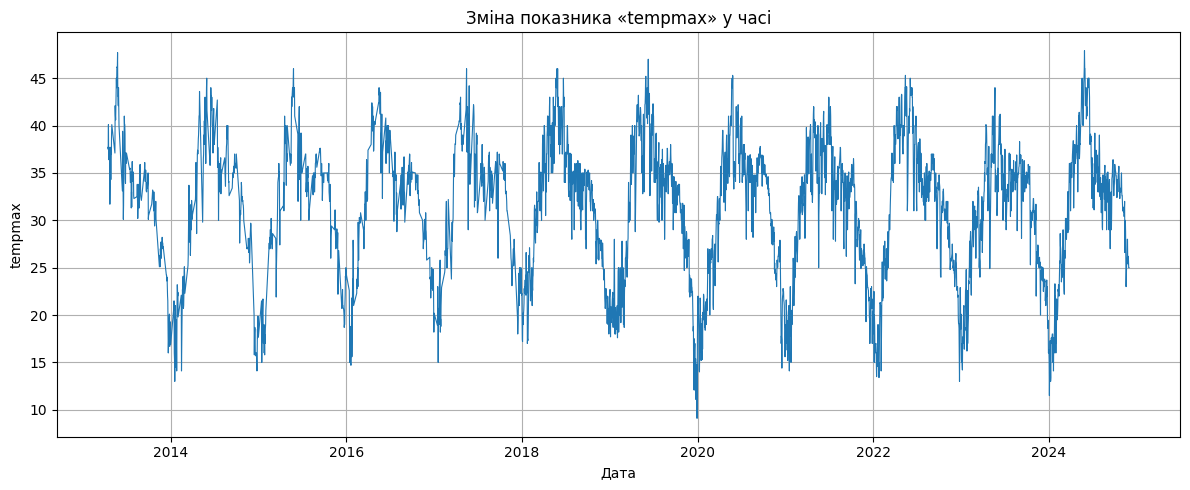

In [7]:
# Побудуйте графік зміни температури у часі

temp_candidates = [c for c in df.columns if "temp" in c.lower() or "temperature" in c.lower()]
if not temp_candidates:
    numeric = df.select_dtypes(include=np.number).columns.tolist()
    if not numeric:
        raise ValueError("У датасеті немає числових колонок для аналізу.")
    temp_col = numeric[0]
else:
    temp_col = temp_candidates[0]
series = pd.to_numeric(df[temp_col], errors="coerce").dropna()
print("Показник для прогнозування:", temp_col)
plt.figure()
plt.plot(series.index, series.values, linewidth=0.8)
plt.title(f"Зміна показника «{temp_col}» у часі")
plt.xlabel("Дата"); plt.ylabel(temp_col); plt.tight_layout(); plt.show()

Ковзне середнє

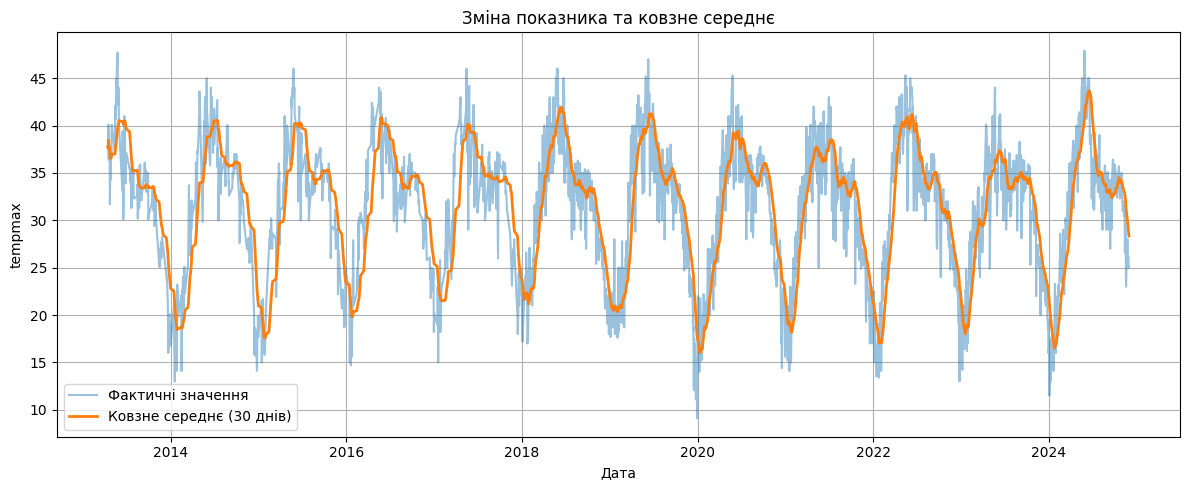

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури

rolling_mean = series.rolling(window=30, min_periods=1).mean()
plt.figure()
plt.plot(series.index, series.values, alpha=0.45, label="Фактичні значення")
plt.plot(rolling_mean.index, rolling_mean.values, linewidth=2, label="Ковзне середнє (30 днів)")
plt.title("Зміна показника та ковзне середнє")
plt.xlabel("Дата"); plt.ylabel(temp_col); plt.legend(); plt.tight_layout(); plt.show()

Розподіл температури

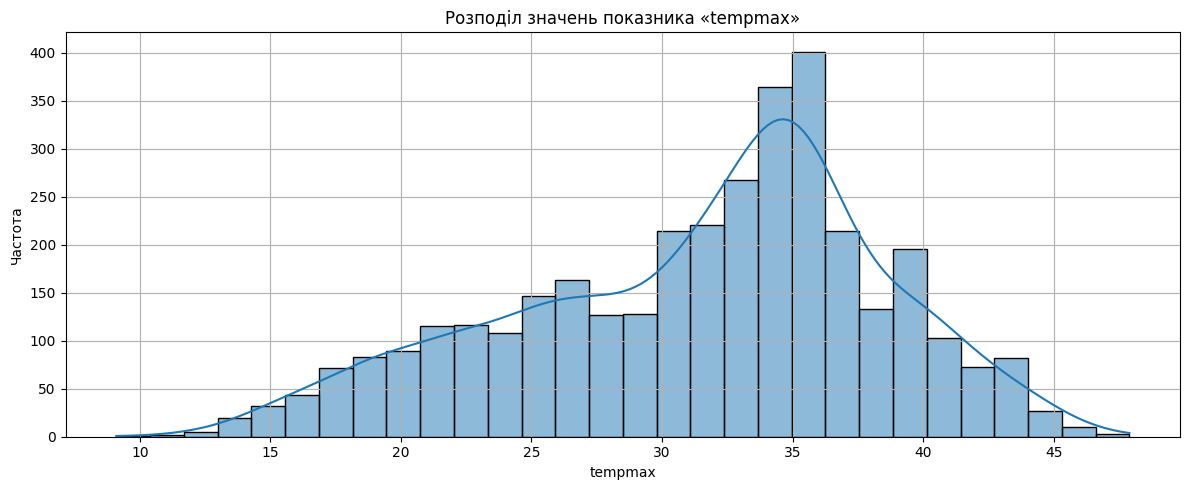

In [9]:
# Побудуйте гістограму розподілу температури

plt.figure()
sns.histplot(series, bins=30, kde=True)
plt.title(f"Розподіл значень показника «{temp_col}»")
plt.xlabel(temp_col); plt.ylabel("Частота"); plt.tight_layout(); plt.show()

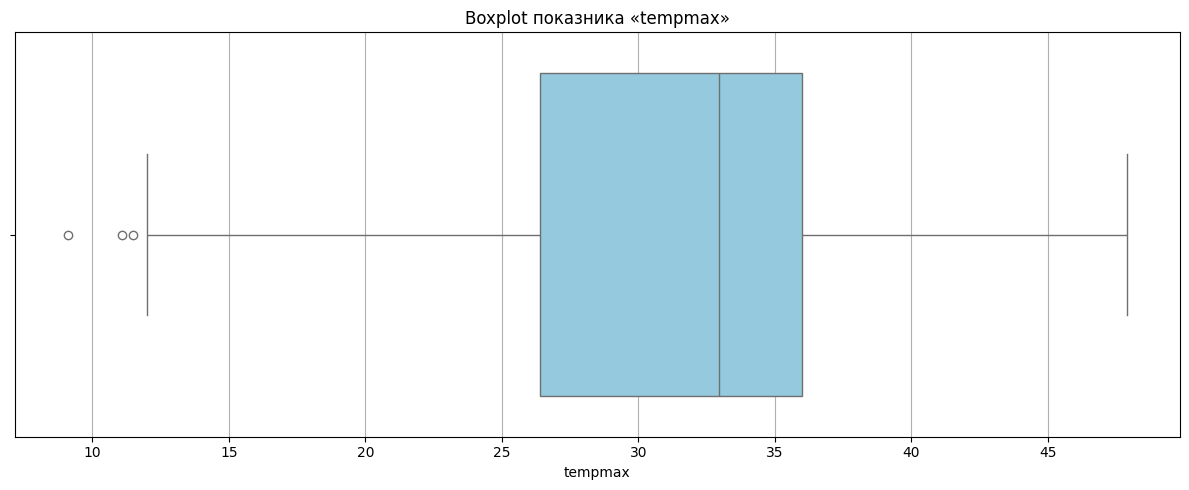

Кількість можливих викидів за правилом IQR: 3


In [10]:
# Побудуйте boxplot температури для аналізу викидів

plt.figure()
sns.boxplot(x=series, color="skyblue")
plt.title(f"Boxplot показника «{temp_col}»")
plt.xlabel(temp_col); plt.tight_layout(); plt.show()
q1, q3 = series.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = series[(series < q1 - 1.5*iqr) | (series > q3 + 1.5*iqr)]
print(f"Кількість можливих викидів за правилом IQR: {len(outliers)}")

Аналіз автокореляції
ACF

PACF

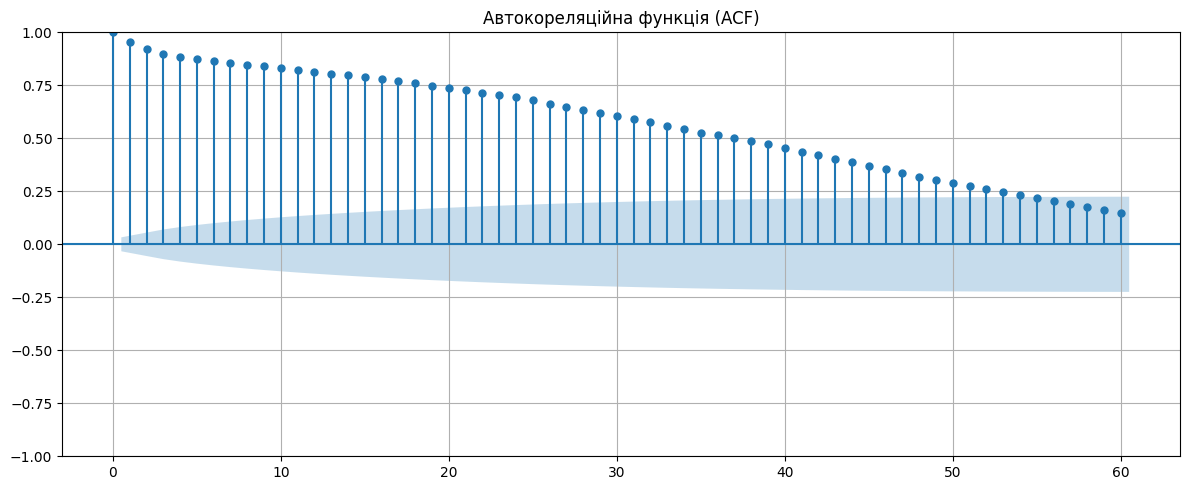

In [11]:
# Побудуйте графік автокореляційної функції (ACF)

acf_values = series.dropna()
plot_acf(acf_values, lags=min(60, max(1, len(acf_values)//2 - 1)))
plt.title("Автокореляційна функція (ACF)")
plt.tight_layout(); plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

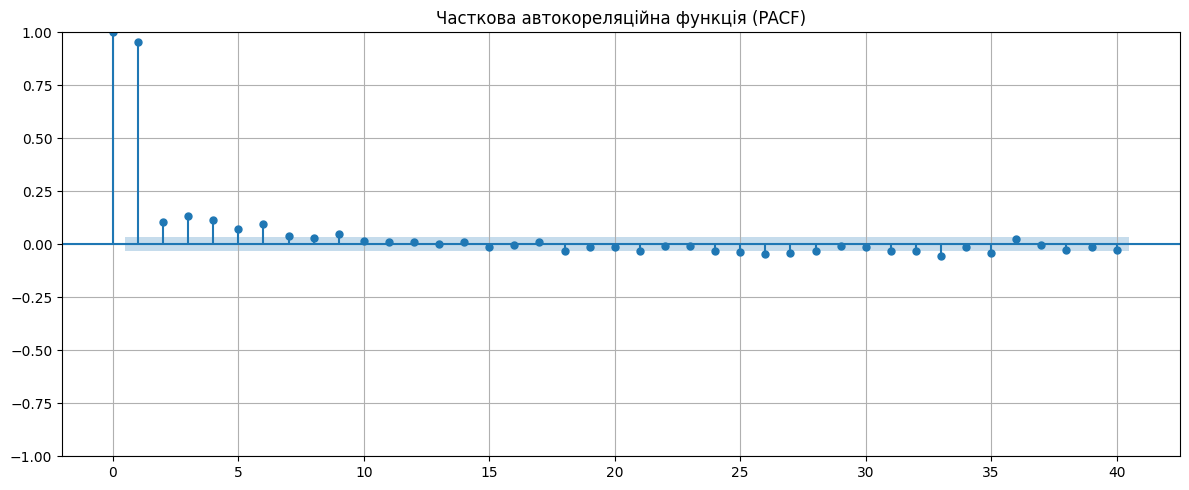

In [12]:
# Побудуйте графік часткової автокореляційної функції (PACF)

pacf_series = series.dropna()
max_lags = min(40, max(1, len(pacf_series)//2 - 1))
plot_pacf(pacf_series, lags=max_lags, method="ywm")
plt.title("Часткова автокореляційна функція (PACF)")
plt.tight_layout(); plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку

y = series.astype(float).sort_index()
y = y[~y.index.duplicated(keep="last")].asfreq("D")
y = y.interpolate(method="time").ffill().bfill()
split_idx = int(len(y) * 0.8)
train, test = y.iloc[:split_idx], y.iloc[split_idx:]
if len(train) < 50 or len(test) < 10:
    raise ValueError("Недостатньо спостережень для надійного навчання та тестування.")
print(f"Кількість спостережень: {len(y)}")
print(f"Train: {len(train)} ({len(train)/len(y):.1%})")
print(f"Test: {len(test)} ({len(test)/len(y):.1%})")
print(f"Період тесту: {test.index.min().date()} — {test.index.max().date()}")

Кількість спостережень: 4249
Train: 3399 (80.0%)
Test: 850 (20.0%)
Період тесту: 2022-08-04 — 2024-11-30


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки

arima_model = ARIMA(train, order=(2, 1, 2), enforce_stationarity=False, enforce_invertibility=False)
arima_fit = arima_model.fit()
arima_forecast = pd.Series(arima_fit.forecast(steps=len(test)), index=test.index, name="ARIMA")
display(arima_forecast.head())
print("ARIMA-модель навчена.")

,ARIMA
DATE,
2022-08-04,33.745765
2022-08-05,33.657585
2022-08-06,33.623642
2022-08-07,33.609685
2022-08-08,33.603734


ARIMA-модель навчена.


In [15]:
# Виведіть статистичний звіт навченої ARIMA-моделі

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                tempmax   No. Observations:                 3399
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -6827.758
Date:                Sat, 10 Oct 2026   AIC                          13665.516
Time:                        15:26:10   BIC                          13696.166
Sample:                    04-14-2013   HQIC                         13676.471
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6501      0.255      2.550      0.011       0.150       1.150
ar.L2         -0.0920      0.167     -0.550      0.582      -0.420       0.236
ma.L1         -0.8183      0.256     -3.194      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

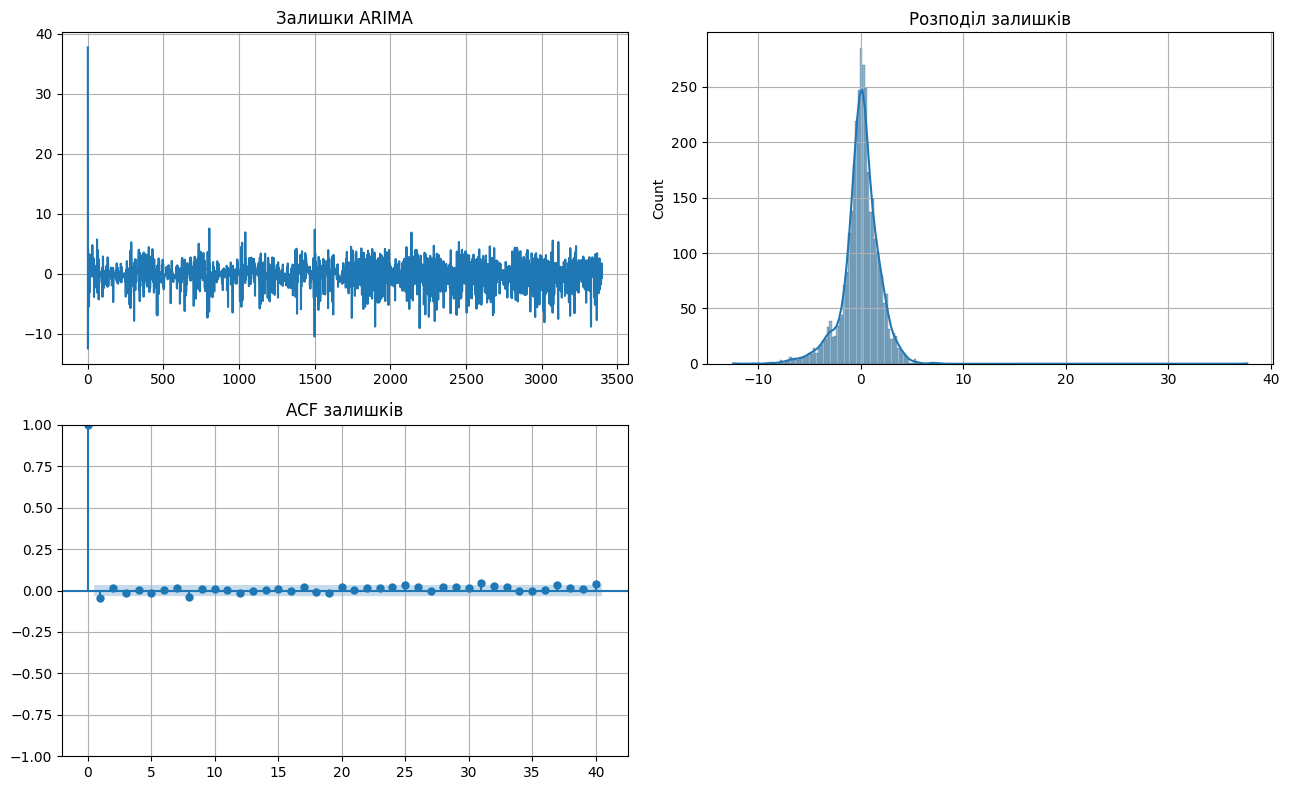

,lb_stat,lb_pvalue
10,15.329312,0.120509


In [16]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки

residuals = pd.Series(arima_fit.resid).dropna()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0,0].plot(residuals.values); axes[0,0].set_title("Залишки ARIMA")
sns.histplot(residuals, kde=True, ax=axes[0,1]); axes[0,1].set_title("Розподіл залишків")
plot_acf(residuals, lags=min(40, max(1, len(residuals)//2 - 1)), ax=axes[1,0])
axes[1,0].set_title("ACF залишків")
axes[1,1].axis("off")
plt.tight_layout(); plt.show()
try:
    display(acorr_ljungbox(residuals, lags=[10], return_df=True))
except Exception as e:
    print("Не вдалося обчислити тест Ljung–Box:", e)

In [17]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = np.abs(actual) > 1e-8
    mape = np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100 if nonzero.any() else np.nan
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}

arima_metrics = calculate_metrics(test, arima_forecast)
print(arima_metrics)

{'MAE': 5.234323259460196, 'RMSE': np.float64(7.087574577734337), 'MAPE (%)': np.float64(21.52085806414509)}


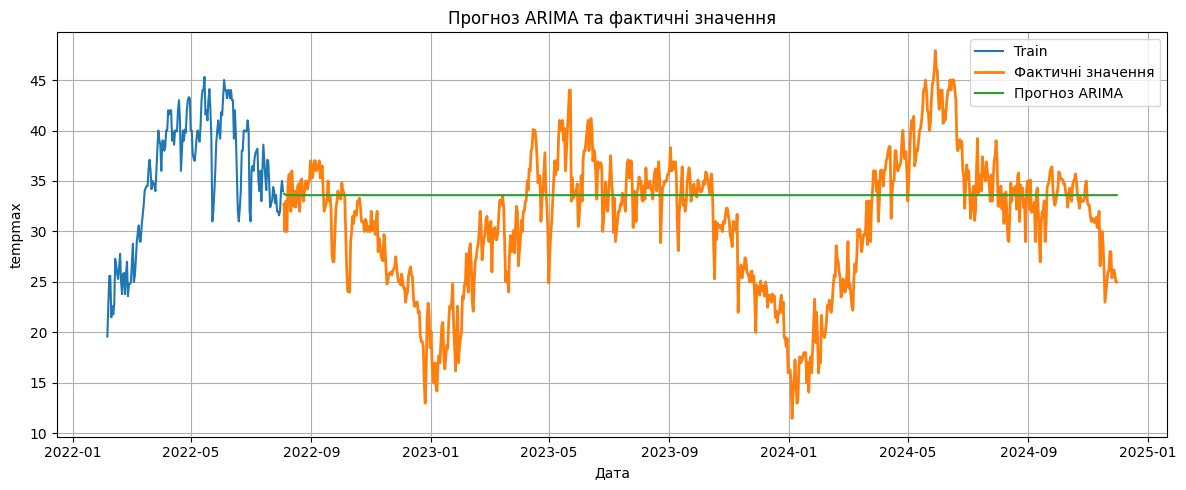

In [18]:
# Візуалізуйте фактичні значення та прогноз ARIMA

plt.figure()
plt.plot(train.index[-min(180, len(train)):], train.iloc[-min(180, len(train)):], label="Train")
plt.plot(test.index, test, label="Фактичні значення", linewidth=2)
plt.plot(arima_forecast.index, arima_forecast, label="Прогноз ARIMA")
plt.title("Прогноз ARIMA та фактичні значення")
plt.xlabel("Дата"); plt.ylabel(temp_col); plt.legend(); plt.tight_layout(); plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
# Підготуйте дані у форматі, необхідному для Prophet

prophet_train = train.rename_axis("ds").reset_index()
prophet_train.columns = ["ds", "y"]
prophet_test = test.rename_axis("ds").reset_index()
prophet_test.columns = ["ds", "y"]
display(prophet_train.head())

,ds,y
0,2013-04-14,37.7
1,2013-04-15,37.5
2,2013-04-16,40.1
3,2013-04-17,36.4
4,2013-04-18,37.5


In [20]:
# Створіть та навчіть модель Prophet

prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
prophet_model.fit(prophet_train)
print("Модель Prophet навчена.")

Модель Prophet навчена.


Прогноз

In [21]:
# Побудуйте прогноз Prophet для тестового періоду

future = pd.DataFrame({"ds": test.index})
prophet_result = prophet_model.predict(future)
prophet_forecast = pd.Series(prophet_result["yhat"].to_numpy(), index=test.index, name="Prophet")
display(prophet_forecast.head())

,Prophet
DATE,
2022-08-04,33.937177
2022-08-05,33.971244
2022-08-06,33.964500
2022-08-07,34.120878
2022-08-08,34.224307


In [22]:
# Обчисліть MAE, RMSE, MAPE для Prophet

prophet_metrics = calculate_metrics(test, prophet_forecast)
print(prophet_metrics)

{'MAE': 2.4871649480698417, 'RMSE': np.float64(3.2635129373768397), 'MAPE (%)': np.float64(8.999084992813021)}


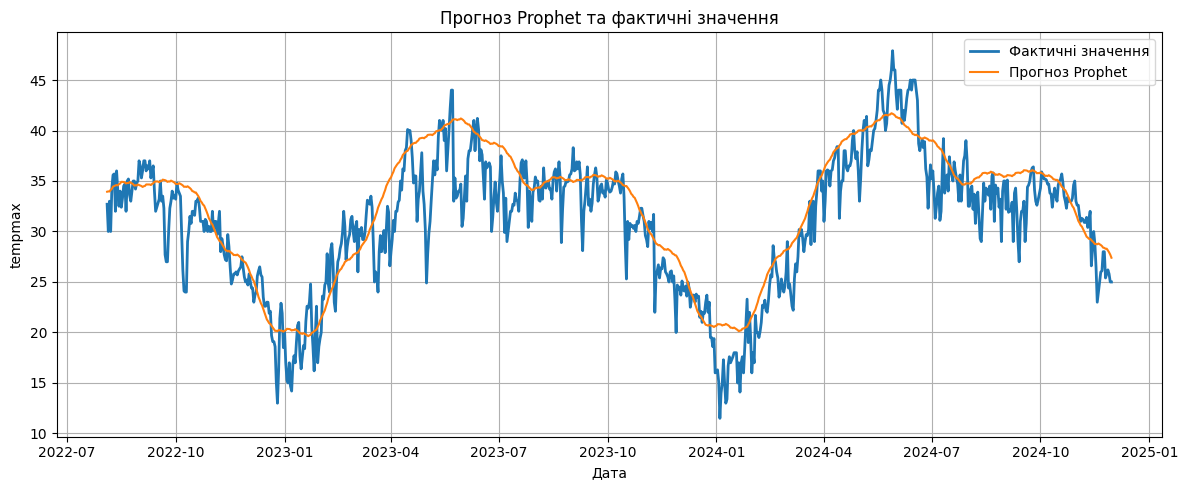

In [23]:
# Візуалізуйте фактичні значення та прогноз Prophet

plt.figure()
plt.plot(test.index, test.values, label="Фактичні значення", linewidth=2)
plt.plot(prophet_forecast.index, prophet_forecast.values, label="Прогноз Prophet")
plt.title("Прогноз Prophet та фактичні значення")
plt.xlabel("Дата"); plt.ylabel(temp_col); plt.legend(); plt.tight_layout(); plt.show()

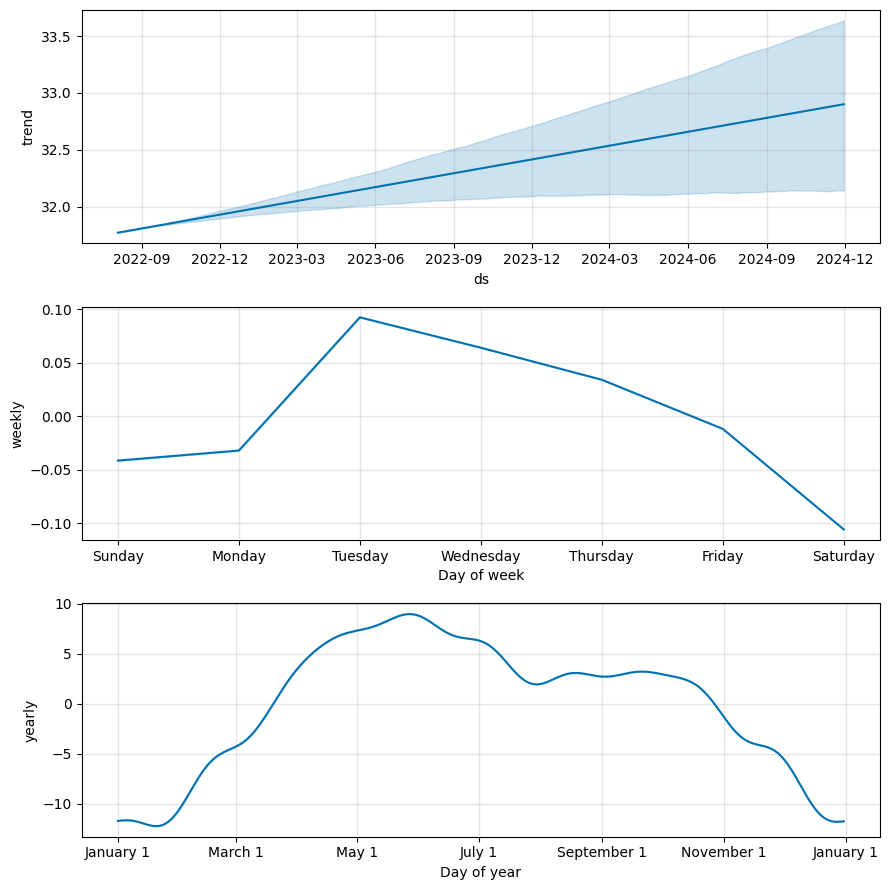

In [24]:
# Побудуйте компоненти моделі Prophet

fig_components = prophet_model.plot_components(prophet_result)
plt.tight_layout(); plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM

scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1))
# Використовуємо попередні 30 днів для прогнозу наступного дня.
LOOKBACK = 30
def make_sequences(values, lookback):
    X, y_out = [], []
    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i, 0])
        y_out.append(values[i, 0])
    return np.asarray(X), np.asarray(y_out)
X_train, y_train = make_sequences(train_scaled, LOOKBACK)
print("X_train:", X_train.shape, "y_train:", y_train.shape)

X_train: (3369, 30) y_train: (3369,)


In [26]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування

all_scaled = scaler.transform(y.to_numpy().reshape(-1, 1))
X_all, y_all = make_sequences(all_scaled, LOOKBACK)
sequence_dates = y.index[LOOKBACK:]
test_mask = sequence_dates.isin(test.index)
X_test = X_all[test_mask]
y_test_scaled = y_all[test_mask]
lstm_test_dates = sequence_dates[test_mask]
print("X_test:", X_test.shape, "y_test:", y_test_scaled.shape)
assert len(lstm_test_dates) == len(test), "Кількість прогнозів LSTM має відповідати тестовій вибірці."

X_test: (850, 30) y_test: (850,)


In [27]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її

X_train_lstm = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_lstm = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
lstm_model = Sequential([
    LSTM(32, input_shape=(LOOKBACK, 1), return_sequences=True),
    Dropout(0.1),
    LSTM(16),
    Dense(16, activation="relu"),
    Dense(1)
])
lstm_model.compile(optimizer="adam", loss="mean_squared_error")
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,777 (30.38 KB)

 Trainable params: 7,777 (30.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.0393 - val_loss: 0.0086
Epoch 2/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0074 - val_loss: 0.0065
Epoch 3/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0065 - val_loss: 0.0062
Epoch 4/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0061 - val_loss: 0.0059
Epoch 5/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0058 - val_loss: 0.0056
Epoch 6/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0055 - val_loss: 0.0054
Epoch 7/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0054 - val_loss: 0.0052
Epoch 8/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0052 - val_loss: 0.0051
Epoch 9/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0050 - val_loss: 0.0049
Epoch 10/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0048 - val_loss: 0.0049
Epoch 11/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0048 - val_loss: 0.0048
Epoch 12/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0047 - val

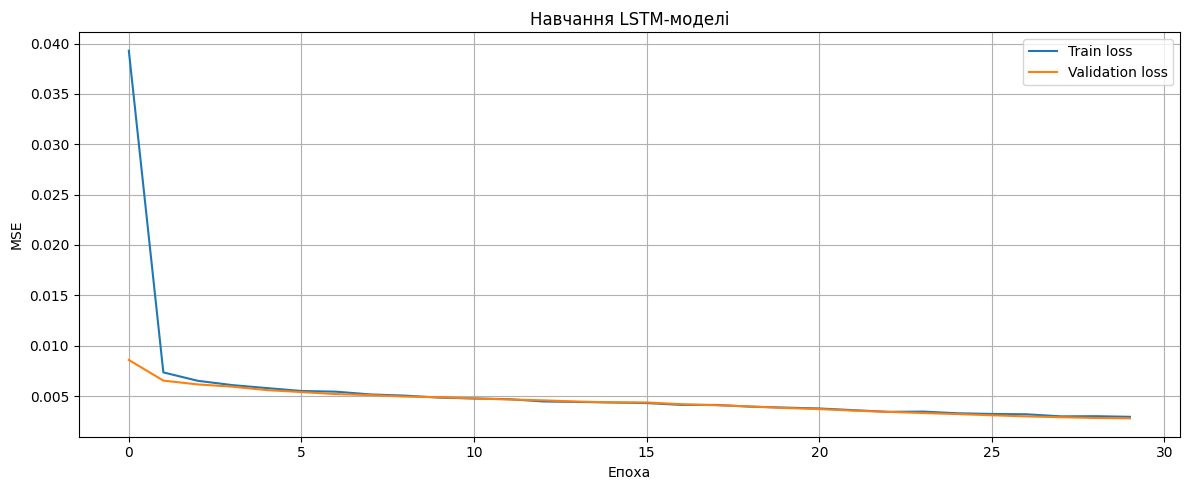

In [28]:
# Навчіть LSTM-модель

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = lstm_model.fit(
    X_train_lstm, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)
plt.figure()
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Навчання LSTM-моделі")
plt.xlabel("Епоха"); plt.ylabel("MSE"); plt.legend(); plt.tight_layout(); plt.show()

In [29]:
# Виведіть структуру LSTM-моделі

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,333 (91.15 KB)

 Trainable params: 7,777 (30.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 15,556 (60.77 KB)

In [30]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування

lstm_pred_scaled = lstm_model.predict(X_test_lstm, verbose=0)
lstm_pred = scaler.inverse_transform(lstm_pred_scaled).ravel()
lstm_actual = scaler.inverse_transform(y_test_scaled.reshape(-1, 1)).ravel()
lstm_forecast = pd.Series(lstm_pred, index=lstm_test_dates, name="LSTM")
lstm_actual_series = pd.Series(lstm_actual, index=lstm_test_dates, name="Actual")
display(lstm_forecast.head())

,LSTM
DATE,
2022-08-04,33.613674
2022-08-05,32.769550
2022-08-06,31.096844
2022-08-07,32.019310
2022-08-08,30.995129


In [31]:
# Сформуйте часові мітки для тестового прогнозу LSTM

lstm_test_dates = pd.DatetimeIndex(lstm_test_dates)
print("Перший день тестового прогнозу:", lstm_test_dates.min().date())
print("Останній день тестового прогнозу:", lstm_test_dates.max().date())
print("Кількість прогнозів:", len(lstm_test_dates))

Перший день тестового прогнозу: 2022-08-04
Останній день тестового прогнозу: 2024-11-30
Кількість прогнозів: 850


In [32]:
# Обчисліть MAE, RMSE, MAPE для LSTM

lstm_metrics = calculate_metrics(lstm_actual, lstm_pred)
print(lstm_metrics)

{'MAE': 1.4985783184275907, 'RMSE': np.float64(1.9601416192496097), 'MAPE (%)': np.float64(5.26454735492366)}


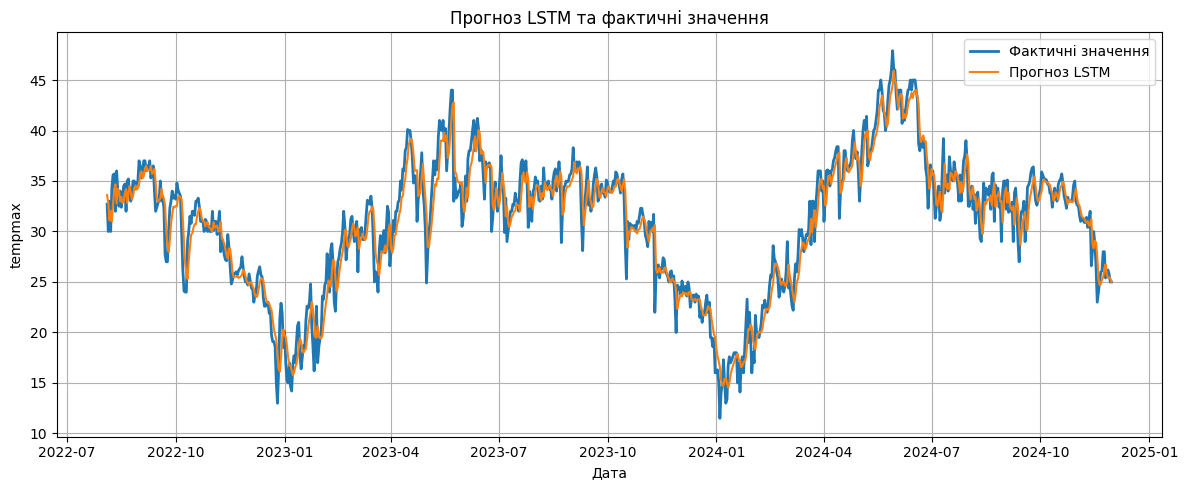

In [33]:
# Візуалізуйте фактичні значення та прогноз LSTM

plt.figure()
plt.plot(lstm_actual_series.index, lstm_actual_series.values, label="Фактичні значення", linewidth=2)
plt.plot(lstm_forecast.index, lstm_forecast.values, label="Прогноз LSTM")
plt.title("Прогноз LSTM та фактичні значення")
plt.xlabel("Дата"); plt.ylabel(temp_col); plt.legend(); plt.tight_layout(); plt.show()

Порівняння моделей

,MAE,RMSE,MAPE (%)
ARIMA,5.2343,7.0876,21.5209
Prophet,2.4872,3.2635,8.9991
LSTM,1.4986,1.9601,5.2645


Найкраща модель за RMSE: LSTM
Інтерпретація: менші значення MAE та RMSE означають меншу середню помилку прогнозу. MAPE подано у відсотках; його слід трактувати обережно, якщо фактичні значення близькі до нуля.


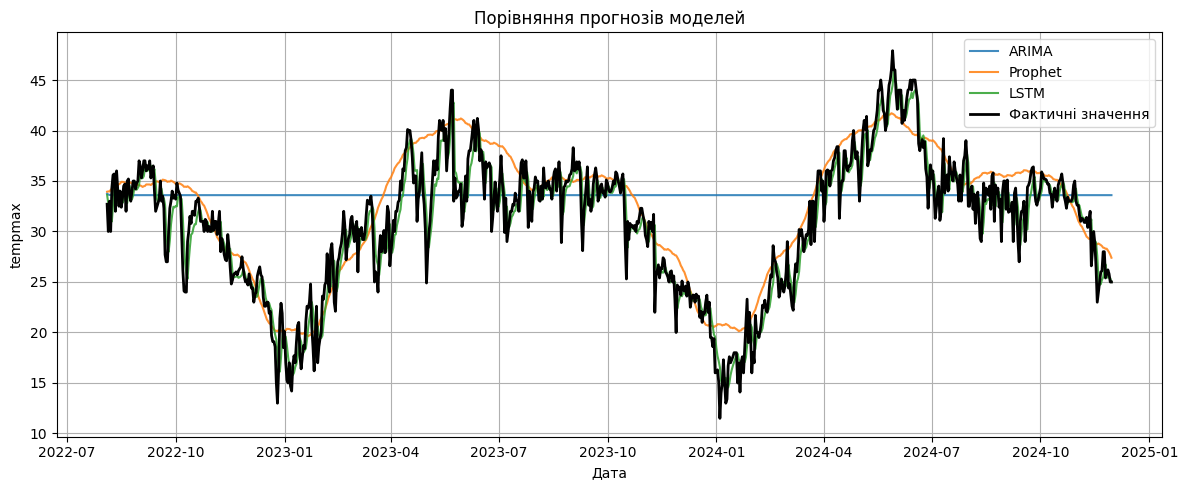

In [34]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами

metrics_df = pd.DataFrame({
    "ARIMA": arima_metrics,
    "Prophet": prophet_metrics,
    "LSTM": lstm_metrics
}).T
display(metrics_df.round(4))

best_model = metrics_df["RMSE"].idxmin()
print(f"Найкраща модель за RMSE: {best_model}")
print("Інтерпретація: менші значення MAE та RMSE означають меншу середню помилку прогнозу. "
      "MAPE подано у відсотках; його слід трактувати обережно, якщо фактичні значення близькі до нуля.")

plt.figure()
for name, forecast in [
    ("ARIMA", arima_forecast),
    ("Prophet", prophet_forecast),
    ("LSTM", lstm_forecast)
]:
    plt.plot(forecast.index, forecast.values, label=name, alpha=0.85)
plt.plot(test.index, test.values, label="Фактичні значення", color="black", linewidth=2)
plt.title("Порівняння прогнозів моделей")
plt.xlabel("Дата"); plt.ylabel(temp_col); plt.legend(); plt.tight_layout(); plt.show()

## Висновок

В ході виконання лабораторної роботи № 5 на тему «Часові ряди» було розглянуто основні методи аналізу та прогнозування часових рядів із використанням мови програмування Python. Було виконано завантаження та попередню обробку даних, перевірено структуру набору даних і наявність пропущених значень.

Для дослідження часового ряду побудовано графіки зміни температури, ковзного середнього, гістограму розподілу, діаграму розмаху, а також графіки автокореляційної та часткової автокореляційної функцій. Ці інструменти дають змогу проаналізувати динаміку даних, їхній розподіл і залежність між спостереженнями в часі.

Також було розглянуто та реалізовано три підходи до прогнозування: ARIMA, Prophet і LSTM. Для оцінювання точності прогнозів використано метрики MAE, RMSE та MAPE, що дозволяють порівняти результати роботи моделей і визначити їхню ефективність на тестовій вибірці.

Отже, під час виконання лабораторної роботи було закріплено навички обробки часових рядів, їхньої візуалізації, побудови прогнозних моделей та оцінювання якості прогнозування. Отримані знання можна використовувати для аналізу даних і прогнозування майбутніх значень на основі історичних спостережень.